## Structure from Motion

Goal: recover the **camera poses** and a **3D point cloud** of an object from a set of 2D images,
one step at a time and visualizing every stage

## Dataset: Middlebury TempleRing

- Source: https://vision.middlebury.edu/mview/data/
- Object: plaster replica of the *Temple of the Dioskouroi* (Agrigento, Sicily)
- **47 images** (`templeR0001.png` … `templeR0047.png`), **640 × 480** pixels
- Cameras lie on a **ring** around the object, all looking at its center
- Images are already **corrected for radial distortion** → no distortion coefficients needed
- Units are roughly **meters**: the object fits in a box of about 10 × 16 × 7 cm,
  and the cameras are about 0.5 m away from it
- Some images are rotated by **180°** (taken "upside down") because of how the capture gantry works

#### Camera parameters: `templeR_par.txt`

The first line is the number of images (`47`). Every following line is:

```
imgname.png  k11 k12 k13 k21 k22 k23 k31 k32 k33  r11 r12 r13 r21 r22 r23 r31 r32 r33  t1 t2 t3
```

### Intrinsics $K$ matrix

$$
K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}
  = \begin{bmatrix} 1520.4 & 0 & 302.32 \\ 0 & 1525.9 & 246.87 \\ 0 & 0 & 1 \end{bmatrix}
$$

- $f_x, f_y$: focal length in pixels
- $c_x, c_y$: principal point (where the optical axis hits the image), close to the image center (320, 240)

### Extrinsics $R$, $t$

$R$ (3×3 rotation) and $t$ (3×1 translation) map a point from **world** coordinates
to **camera** coordinates:

$$
X_{cam} = R \, X_{world} + t
$$

### Projection

A 3D world point $X$ lands on pixel $(u, v)$:

$$
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \, [R \mid t] \begin{bmatrix} X \\ 1 \end{bmatrix}
$$

The image origin is the **top-left** corner, $u$ grows to the right and $v$ grows downwards.

### Useful quantities

- **Camera center** in world coordinates (the point that maps to $X_{cam} = 0$):
  $$C = -R^\top t$$
- **Viewing direction** (the camera's $z$ axis in world coordinates) = third row of $R$:
  $$d = R^\top \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix}$$
- A valid rotation satisfies $R R^\top = I$ and $\det R = +1$

## Pipeline

**Sparse reconstruction (SfM)**

1. Load the images, K and the ground-truth poses
2. Detect **SIFT** features and match them between two images (ratio test)
3. First two images: Essential matrix + RANSAC → relative pose $(R, t)$
4. Triangulate the first 3D points
5. Find the order of the images around the ring (most matches first)
6. Add every next image with **PnP**, triangulate the new points
7. Compare the camera trajectory with the ground truth (ATE, rotation error)

**Dense reconstruction**

8. Rectify neighboring image pairs
9. Disparity with SGBM, depth map, left–right check
10. Back-project every pixel to 3D and merge all pairs into one point cloud

**Surface**

11. Poisson surface reconstruction → triangle mesh

### Pinhole camera

![Pinhole camera model](pinhole_camera_model.png)

*Figure: OpenCV documentation, Camera Calibration and 3D Reconstruction.*

![Forward projection](forward_projection.png)

*Figure: Robert Collins, CMPEN497 lecture slides (Penn State).*

A world point is first moved into the camera frame ($X_{cam} = R\,X_{world} + t$), then projected to a pixel:

$$u = f_x \frac{X}{Z} + c_x \qquad v = f_y \frac{Y}{Z} + c_y$$

![Basic perspective projection](perspective_projection.png)

*Figure: Robert Collins, CMPEN454 lecture slides (Penn State).*

The two similar triangles give $x = f\,X/Z$: a point twice as far away appears half as large.
Going back from a pixel to 3D is only possible if we know $Z$. That is what stereo gives us.

### One camera, "virtual stereo"

We have **one camera** that moves around the temple. The temple does not move, so two photos from neighboring positions work like a stereo pair.

- **Baseline B:** different for every pair, taken from our SfM poses: ‖T_ab‖
- **Rectification:** the two cameras are rotated relative to each other, so we align them with `stereoRectify`
- **Search direction:** the camera moves up/down along the ring, so the matches lie on vertical lines → we rotate the images by 90°

In [29]:
%matplotlib inline


import numpy as np
import matplotlib.pyplot as plt
import cv2

EPS = 1e-8

In [30]:
# Load data

par_path = "templeRing/templeR_par.txt"

with open(par_path) as f:
    lines = f.read().splitlines()

n_images = int(lines[0])

names, Ks, Rs, ts = [], [], [], []

for line in lines[1:]:

    if not line.strip():
        continue
    parts = line.split()

    name = parts[0]
    K = np.array(parts[1:10], dtype=float).reshape(3, 3)   
    R = np.array(parts[10:19], dtype=float).reshape(3, 3)   
    t = np.array(parts[19:22], dtype=float)                 

    names.append(name)
    Ks.append(K)
    Rs.append(R)
    ts.append(t)

Ks, Rs, ts = np.array(Ks), np.array(Rs), np.array(ts)

print("images:", n_images, len(names))
print("K =\n", Ks[0])
print("R R^T =\n", np.round(Rs[0] @ Rs[0].T, 6))
print("det R =", np.linalg.det(Rs[0]))
print("t =", ts[0])

images: 47 47
K =
 [[1.5204e+03 0.0000e+00 3.0232e+02]
 [0.0000e+00 1.5259e+03 2.4687e+02]
 [0.0000e+00 0.0000e+00 1.0000e+00]]
R R^T =
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]
det R = 0.9999999999999998
t = [-0.02921495 -0.02419239  0.52269562]


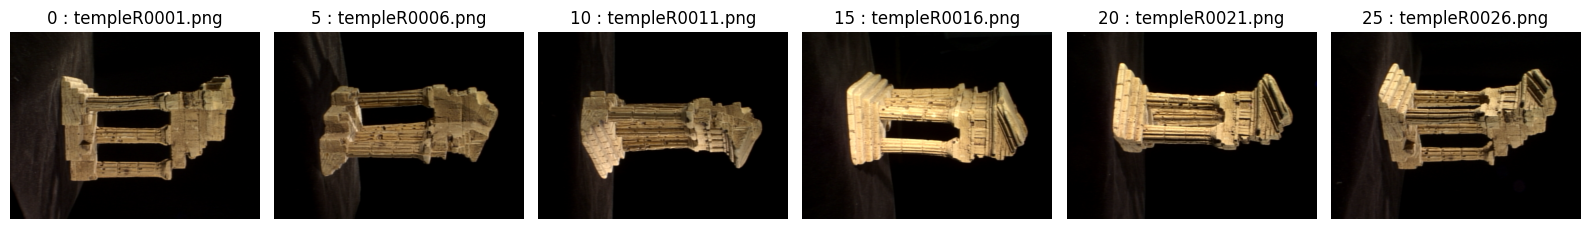

In [31]:
image_folder = "templeRing"
show_ids = [0, 5, 10, 15, 20, 25]

fig, axes = plt.subplots(1, len(show_ids), figsize=(16,4))

for ax, i in zip(axes, show_ids):
    img = cv2.imread(f"{image_folder}/{names[i]}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(f"{i} : {names[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

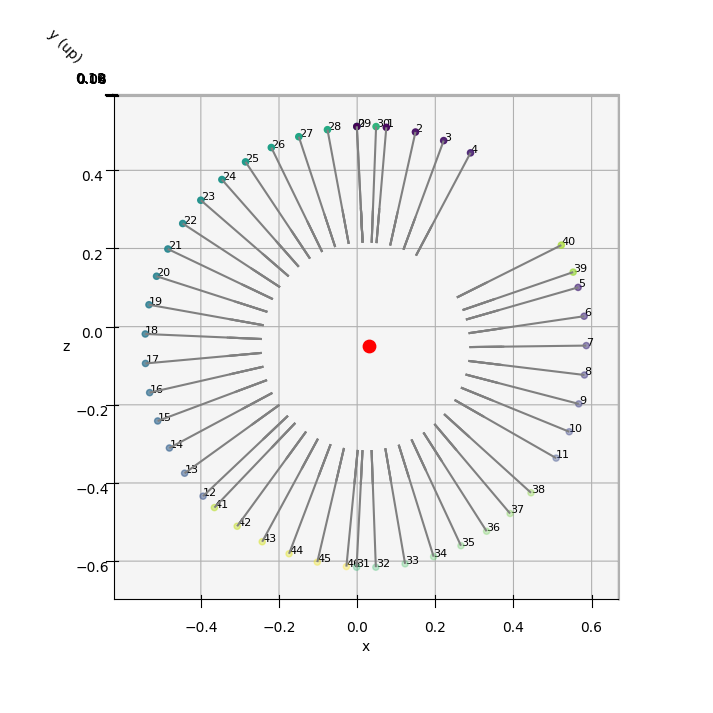

In [32]:
# Camera's position in world coordinates
# X_Camera = R.X_World + t
# Camera coords is always (0, 0, 0)
# 0 = R .C + t
# R.C = -t
# R^T. R . C = -R^T. T
# C = -R^T. t

centers = []
directions = []

for R, t in zip(Rs, ts):
    C = -R.T @ t
    d = R[2]
    centers.append(C)
    directions.append(d)

centers = np.array(centers)
directions = np.array(directions)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(projection="3d")

ax.scatter(centers[:, 0], centers[:, 2], centers[:, 1], c=np.arange(len(centers)), cmap="viridis")

ax.quiver(centers[:, 0], centers[:, 2], centers[:, 1],
          directions[:, 0], directions[:, 2], directions[:, 1],
          length=0.3, color="gray")

for i ,C in enumerate(centers):
    ax.text(C[0], C[2], C[1], str(i), fontsize=8)

ax.scatter(0.03, -0.05, 0.04, color="red", s=80, label="temple")
ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_zlabel("y (up)")
ax.set_box_aspect(np.ptp(centers[:, [0, 2, 1]], axis=0))   
ax.view_init(elev=90, azim=-90)

keypoints: 2000
descriptors: (2000, 32) uint8
first keypoint : pt: (145.0, 329.0) size: 31.0


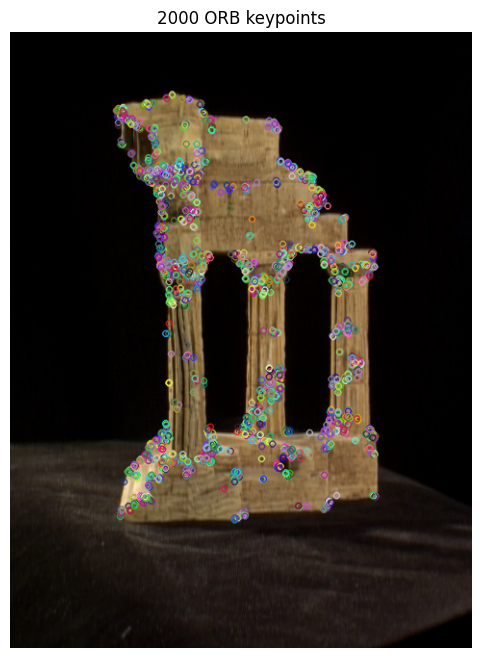

In [33]:
img = cv2.imread(f"{image_folder}/{names[0]}")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create(nfeatures=2000)
keypoints, descriptors = orb.detectAndCompute(gray, None)

print("keypoints:", len(keypoints))
print("descriptors:", descriptors.shape, descriptors.dtype)

kp = keypoints[0]
print("first keypoint : pt:", kp.pt, "size:", kp.size)

vis = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DEFAULT)
plt.figure(figsize=(10, 8))
plt.imshow(cv2.rotate(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB), cv2.ROTATE_90_COUNTERCLOCKWISE))
#plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"{len(keypoints)} ORB keypoints")
plt.axis("off")
plt.show()

In [34]:
def extract_features(image, detector="orb", mask=None, nfeatures=2000):
    if detector == "sift":
        det = cv2.SIFT_create()
    elif detector == "orb":
        det = cv2.ORB_create(nfeatures=nfeatures)

    keypoints, descriptors = det.detectAndCompute(image, mask)
    
    return keypoints, descriptors

def match_features(des1, des2, k=2):
    # SIFT descriptors are float vectors -> L2 distance
    matcher = cv2.BFMatcher_create(cv2.NORM_L2, crossCheck=False)
    matches = matcher.knnMatch(des1, des2, k=k)
    return matches

def filter_matches_distance(matches, ratio=0.75):
    good = []
    for m, n in matches:
        if m.distance <= ratio * n.distance:
            good.append(m)
    return good

def visualize_matches(image1, kp1, image2, kp2, matches):
    image_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=2)
    plt.figure(figsize=(16, 6))
    plt.imshow(image_matches)
    plt.title(f"{len(matches)} matches")
    plt.axis("off")
    plt.show()

before ratio test: 801
after ratio test : 402


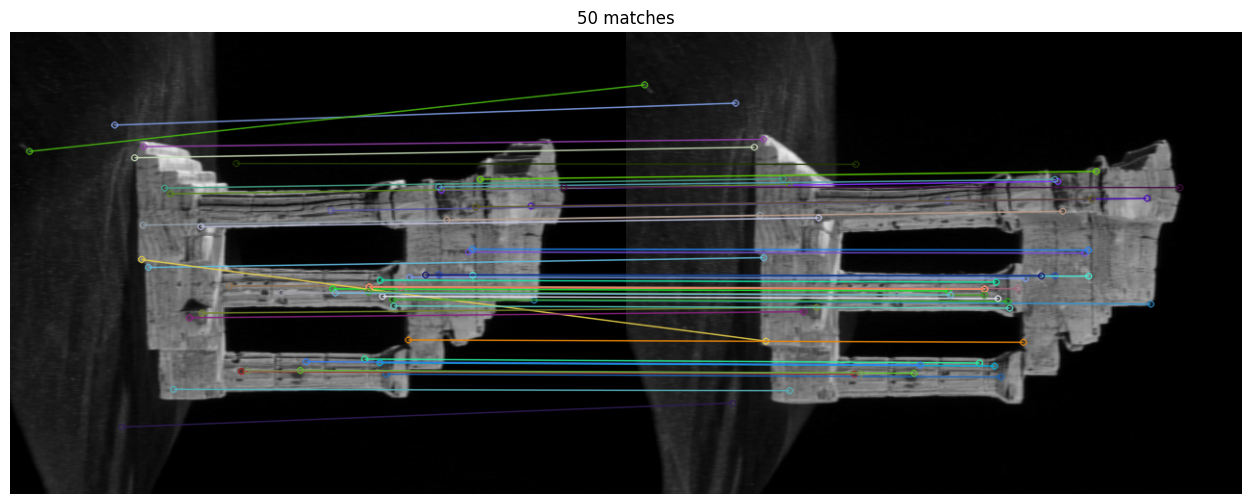

In [35]:
first, second, third = 0, 1, 2

img0 = cv2.imread(f"{image_folder}/{names[first]}", cv2.IMREAD_GRAYSCALE)
img1 = cv2.imread(f"{image_folder}/{names[second]}", cv2.IMREAD_GRAYSCALE)

kp0, des0 = extract_features(img0, "sift")
kp1, des1 = extract_features(img1, "sift")

matches = match_features(des0, des1)
print("before ratio test:", len(matches))
good = filter_matches_distance(matches, 0.75)
print("after ratio test :", len(good))

rng = np.random.default_rng(0)
random_ids = rng.choice(len(good), 50, replace=False)   # 50 random match numbers
sample = []
for i in random_ids:
    sample.append(good[i])
visualize_matches(img0, kp0, img1, kp1, sample)

In [36]:
def get_matched_points(kp0, kp1, matches):
    pts0 = []
    pts1 = []

    for m in matches:
        pts0.append(kp0[m.queryIdx].pt) # pixel (x, y) in image 0
        pts1.append(kp1[m.trainIdx].pt) # pixel (x, y) in image 1

    return np.array(pts0), np.array(pts1)

pts0, pts1 = get_matched_points(kp0, kp1, good)
print("pts0:", pts0.shape)
print("pts1:", pts1.shape)
print("first match:", pts0[0], "--", pts1[0])

pts0: (402, 2)
pts1: (402, 2)
first match: [ 13.05465031 117.91705322] -- [19.0084362  54.35738754]


#### How did the camera move? (R, t)

When the camera moves, every point shifts a little in the image. The shift is not random: it depends on how much the camera rotated (**R**) and which direction it moved (**t**).

We go backwards: from how the matched points shifted, we recover the camera motion.

1. `findEssentialMat` – estimates a 3×3 matrix **E** that encodes the motion. RANSAC rejects wrong matches (marked 0 in `mask`).
2. `recoverPose` – extracts **R** and **t** from E.

Note: t has length 1. Two images give only the direction of motion, not the distance.

In [37]:
K = Ks[0]

E, mask = cv2.findEssentialMat(pts0, pts1, K, method=cv2.RANSAC, prob=0.999, threshold=1.0)
_, R, t, mask = cv2.recoverPose(E, pts0, pts1, K, mask=mask)

print("good matches (inliers):", mask.sum(), "/", len(pts0))
print("R =\n", R)
print("t =", t.ravel())

good matches (inliers): 377 / 402
R =
 [[ 0.99979084 -0.02042514 -0.00104339]
 [ 0.02035817  0.98904328  0.14621535]
 [-0.00195452 -0.14620601  0.98925223]]
t = [ 0.00563663 -0.99794725  0.06379276]


#### From 2D matches to 3D points (Triangulation)

Camera 0 is the reference (R = I, t = 0). Camera 1 uses the R, t we just found.
Each match gives one ray from each camera. The 3D point is where the two rays meet.

`P = K [R | t]` is the projection matrix: it maps a 3D point to a pixel.

3D points: (377, 3)


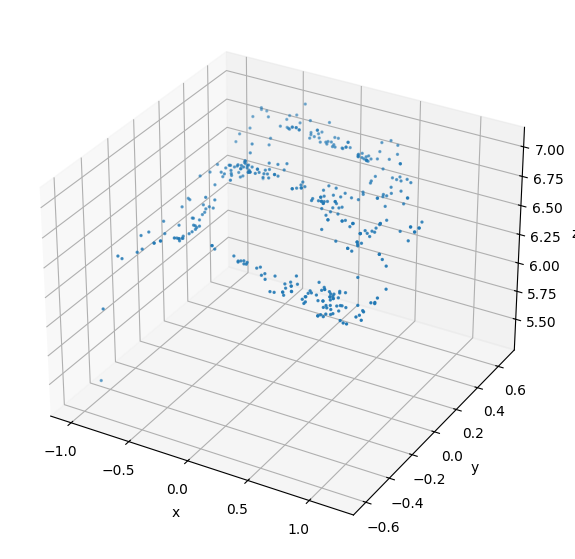

In [38]:
P0 = K @ np.hstack([np.eye(3), np.zeros((3, 1))])   # camera 0
P1 = K @ np.hstack([R, t])                           # camera 1

inliers = mask.ravel() == 1

X_h = cv2.triangulatePoints(P0, P1, pts0[inliers].T, pts1[inliers].T)   # 4 x N
X = (X_h[:3] / X_h[3]).T                                                # N x 3

print("3D points:", X.shape)

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=2)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.show()

#### Adding a new camera (PnP)

We already have 3D points. If some of them are also visible in a new image,
we can find the new camera pose directly from *3D point ↔ pixel* pairs. This is PnP.

To do that we need to know which keypoint of image 1 belongs to which 3D point.

In [39]:
kp1_to_3d = {}
row = 0

obs_cam = []
obs_point = []
obs_pixel = []

for m, is_inlier in zip(good, inliers):
    if is_inlier:
        kp1_to_3d[m.trainIdx] = row
        obs_cam.append(0); obs_point.append(row); obs_pixel.append(kp0[m.queryIdx].pt)
        obs_cam.append(1); obs_point.append(row); obs_pixel.append(kp1[m.trainIdx].pt)
        row += 1

img2 = cv2.imread(f"{image_folder}/{names[third]}", cv2.IMREAD_GRAYSCALE)
kp2, des2 = extract_features(img2, "sift")
good12 = filter_matches_distance(match_features(des1, des2), 0.75)

object_points = []
image_points = []
for m in good12:
    if m.queryIdx in kp1_to_3d:
        object_points.append(X[kp1_to_3d[m.queryIdx]])
        image_points.append(kp2[m.trainIdx].pt)
        obs_cam.append(2); obs_point.append(kp1_to_3d[m.queryIdx]); obs_pixel.append(kp2[m.trainIdx].pt)

object_points = np.array(object_points)
image_points = np.array(image_points)
print("3D-2D pairs:", len(object_points))

ok, rvec, t2, pnp_inliers = cv2.solvePnPRansac(object_points, image_points, K, None)
R2, _ = cv2.Rodrigues(rvec)

print("PnP inliers:", len(pnp_inliers))
print("R2 =\n", R2)
print("t2 =", t2.ravel())

3D-2D pairs: 242
PnP inliers: 238
R2 =
 [[ 0.99915864 -0.04096626 -0.00194164]
 [ 0.03972578  0.9549674   0.29403934]
 [-0.01019149 -0.29386908  0.95579135]]
t2 = [ 0.0107314  -2.00730267  0.27434458]


#### Growing the map

Matches between image 1 and 2 that have no 3D point yet are triangulated with camera 1 and camera 2.
We keep a new point only if it is in front of the camera and projects back close to its pixel (< 2 px).

fresh matches: 167 | kept: 153
total 3D points: 530


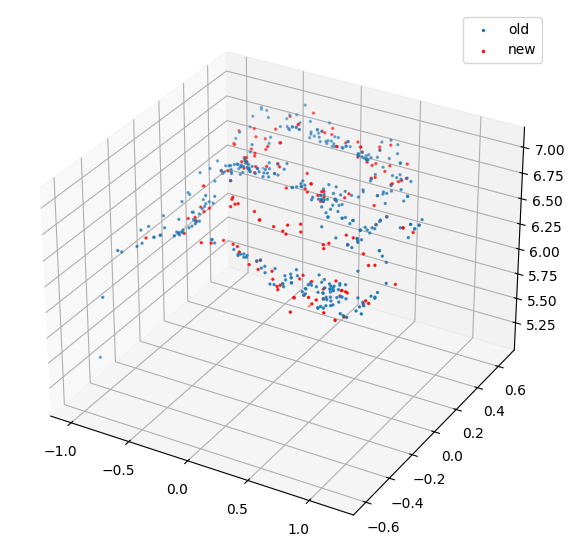

In [40]:
P1 = K @ np.hstack([R, t])
P2 = K @ np.hstack([R2, t2])


fresh = []
for m in good12:
    if m.queryIdx not in kp1_to_3d:
        fresh.append(m)

pts1_new, pts2_new = get_matched_points(kp1, kp2, fresh)

X_h = cv2.triangulatePoints(P1, P2, pts1_new.T, pts2_new.T)
X_new = (X_h[:3] / X_h[3]).T

proj = (P2 @ np.hstack([X_new, np.ones((len(X_new), 1))]).T).T
proj = proj[:, :2] / proj[:, 2:]
error = np.linalg.norm(proj - pts2_new, axis=1)

depth = (R2 @ X_new.T + t2).T[:, 2]

keep = (depth > 0) & (error < 2)
print("fresh matches:", len(fresh), "| kept:", keep.sum())

X_old_count = len(X)
X = np.vstack([X, X_new[keep]])
print("total 3D points:", len(X))

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:X_old_count, 0], X[:X_old_count, 1], X[:X_old_count, 2], s=2, label="old")
ax.scatter(X[X_old_count:, 0], X[X_old_count:, 1], X[X_old_count:, 2], s=2, c="red", label="new")
ax.legend()
plt.show()

## Image order

The file order is not the order around the ring. Starting from image 2, we always pick
the remaining image with the most matches as the next one.

In [41]:
# descriptors of all images
all_des = []
for i in range(len(names)):
    img = cv2.imread(f"{image_folder}/{names[i]}", cv2.IMREAD_GRAYSCALE)
    kp, des = extract_features(img, "sift")
    all_des.append(des)

order = [first, second, third]
current = third

remaining = []
for i in range(len(names)):
    if i not in order:
        remaining.append(i)

while len(remaining) > 0:
    best, best_count = None, 0
    for j in remaining:
        count = len(filter_matches_distance(match_features(all_des[current], all_des[j]), 0.75))
        if count > best_count:
            best, best_count = j, count
    order.append(best)
    remaining.remove(best)
    current = best

print(order)

[0, 1, 2, 3, 4, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 41, 42, 43, 44, 45, 46, 31, 32, 33, 34, 35, 36, 37, 38, 11, 10, 9, 8, 7, 6, 5, 39, 40]


#### All images

For every next image we repeat the same three steps: match with the previous image → PnP → triangulate new points.
`prev_to_3d` remembers which keypoint of the previous image belongs to which 3D point.

In [42]:
prev_to_3d = {}
for m in good12:
    if m.queryIdx in kp1_to_3d:
        prev_to_3d[m.trainIdx] = kp1_to_3d[m.queryIdx]
row = X_old_count
for k in range(len(fresh)):
    if keep[k]:
        prev_to_3d[fresh[k].trainIdx] = row
        obs_cam.append(1); obs_point.append(row); obs_pixel.append(pts1_new[k])
        obs_cam.append(2); obs_point.append(row); obs_pixel.append(pts2_new[k])
        row += 1

poses = [(np.eye(3), np.zeros((3, 1))), (R, t), (R2, t2)]
kp_prev, des_prev = kp2, des2
R_prev, t_prev = R2, t2

for i in order[3:]:
    img = cv2.imread(f"{image_folder}/{names[i]}", cv2.IMREAD_GRAYSCALE)
    kp, des = extract_features(img, "sift")
    good_i = filter_matches_distance(match_features(des_prev, des), 0.75)

    # 1) PnP
    object_points = []
    image_points = []
    for m in good_i:
        if m.queryIdx in prev_to_3d:
            object_points.append(X[prev_to_3d[m.queryIdx]])
            image_points.append(kp[m.trainIdx].pt)
            obs_cam.append(len(poses)); obs_point.append(prev_to_3d[m.queryIdx]); obs_pixel.append(kp[m.trainIdx].pt)

    if len(object_points) < 10:
        print(f"image {i}: not enough 3D points, stop")
        break

    ok, rvec, t_new, pnp_inliers = cv2.solvePnPRansac(np.array(object_points), np.array(image_points), K, None)
    R_new, _ = cv2.Rodrigues(rvec)
    poses.append((R_new, t_new))
    cam = len(poses) - 1

    # 2) triangulate new points
    fresh = []
    for m in good_i:
        if m.queryIdx not in prev_to_3d:
            fresh.append(m)

    pts_prev, pts_new = get_matched_points(kp_prev, kp, fresh)
    P_prev = K @ np.hstack([R_prev, t_prev])
    P_new = K @ np.hstack([R_new, t_new])
    X_h = cv2.triangulatePoints(P_prev, P_new, pts_prev.T, pts_new.T)
    X_new = (X_h[:3] / X_h[3]).T

    proj = (P_new @ np.hstack([X_new, np.ones((len(X_new), 1))]).T).T
    proj = proj[:, :2] / proj[:, 2:]
    error = np.linalg.norm(proj - pts_new, axis=1)
    depth = (R_new @ X_new.T + t_new).T[:, 2]
    keep = (depth > 0) & (error < 2)

    # 3) dictionary for this image
    new_to_3d = {}
    for m in good_i:
        if m.queryIdx in prev_to_3d:
            new_to_3d[m.trainIdx] = prev_to_3d[m.queryIdx]
    row = len(X)
    for k in range(len(fresh)):
        if keep[k]:
            new_to_3d[fresh[k].trainIdx] = row
            obs_cam.append(cam - 1); obs_point.append(row); obs_pixel.append(pts_prev[k])
            obs_cam.append(cam); obs_point.append(row); obs_pixel.append(pts_new[k])
            row += 1

    X = np.vstack([X, X_new[keep]])
    print(f"image {i}: PnP inliers {len(pnp_inliers)}, new points {keep.sum()}, total {len(X)}")

    # this image becomes the previous one
    kp_prev, des_prev = kp, des
    R_prev, t_prev = R_new, t_new
    prev_to_3d = new_to_3d

image 3: PnP inliers 244, new points 164, total 694
image 4: PnP inliers 264, new points 158, total 852
image 30: PnP inliers 90, new points 13, total 865
image 29: PnP inliers 80, new points 366, total 1231
image 28: PnP inliers 260, new points 104, total 1335
image 27: PnP inliers 241, new points 184, total 1519
image 26: PnP inliers 253, new points 195, total 1714
image 25: PnP inliers 284, new points 207, total 1921
image 24: PnP inliers 292, new points 191, total 2112
image 23: PnP inliers 322, new points 182, total 2294
image 22: PnP inliers 299, new points 182, total 2476
image 21: PnP inliers 310, new points 136, total 2612
image 20: PnP inliers 321, new points 146, total 2758
image 19: PnP inliers 309, new points 161, total 2919
image 18: PnP inliers 322, new points 137, total 3056
image 17: PnP inliers 315, new points 110, total 3166
image 16: PnP inliers 285, new points 136, total 3302
image 15: PnP inliers 276, new points 134, total 3436
image 14: PnP inliers 265, new point

observations: 28897
3D points: 7730 | cameras: 47


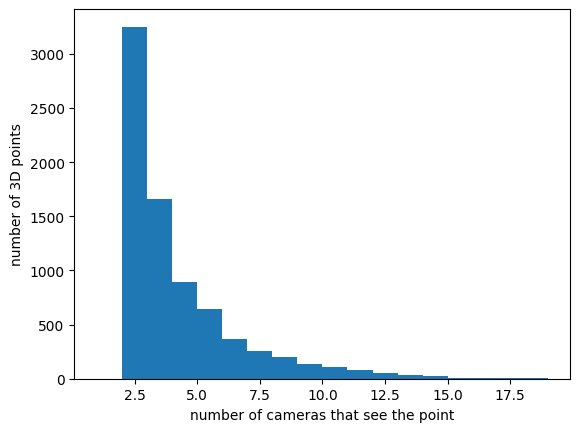

In [43]:
obs_cam = np.array(obs_cam)
obs_point = np.array(obs_point)
obs_pixel = np.array(obs_pixel, dtype=float)

seen_by = np.bincount(obs_point, minlength=len(X))

print("observations:", len(obs_cam))
print("3D points:", len(X), "| cameras:", len(poses))

plt.hist(seen_by, bins=range(1, seen_by.max() + 2))
plt.xlabel("number of cameras that see the point")
plt.ylabel("number of 3D points")
plt.show()

In [44]:
# our camera centers, C = -R^T t
centers = []
for R_i, t_i in poses:
    centers.append((-R_i.T @ t_i).ravel())
centers = np.array(centers)
print("cameras:", len(centers))

cameras: 47


#### How big is the drift?

The par file has the true camera poses (in meters). To compare, we put the true camera centers
in camera 0's frame and scale ours so that the distance between camera 0 and 1 is the true one.

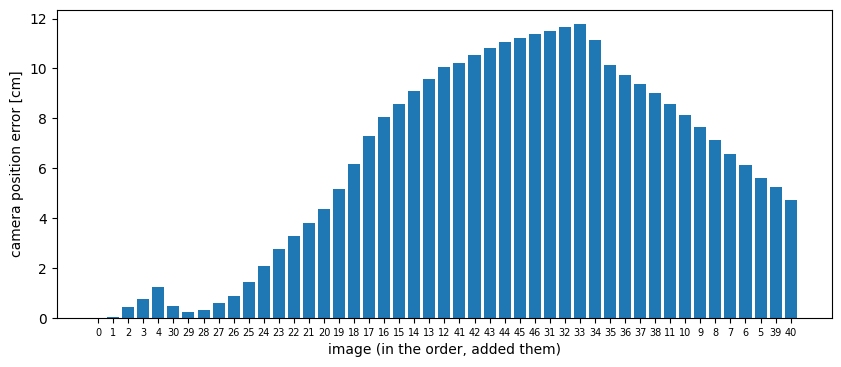

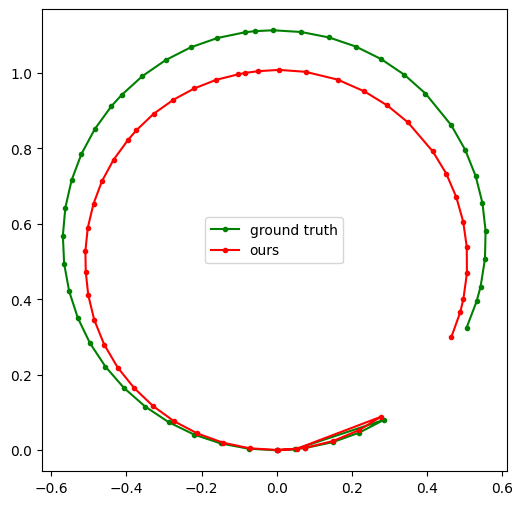

In [45]:
def center(R, t):
    return (-R.T @ np.reshape(t, (3, 1))).ravel()

R0_gt = Rs[0]
t0_gt = np.ravel(ts[0])

# true camera centers, written in camera 0's frame
gt_centers = []
for i in order:
    C = center(Rs[i], ts[i])
    gt_centers.append(R0_gt @ C + t0_gt)
gt_centers = np.array(gt_centers)

# scale: true distance between camera 0 and 1
scale = np.linalg.norm(gt_centers[1] - gt_centers[0])
our_centers = centers * scale

errors_cm = []
for k in range(len(order)):
    errors_cm.append(np.linalg.norm(our_centers[k] - gt_centers[k]) * 100)

plt.figure(figsize=(10, 4))
plt.bar(range(len(order)), errors_cm)
plt.xticks(range(len(order)), order, fontsize=7)
plt.xlabel("image (in the order, added them)")
plt.ylabel("camera position error [cm]")
plt.show()

plt.figure(figsize=(6, 6))
plt.plot(gt_centers[:, 1], gt_centers[:, 2], "g.-", label="ground truth")
plt.plot(our_centers[:, 1], our_centers[:, 2], "r.-", label="ours")
plt.axis("equal")
plt.legend()
plt.show()

## Trajectory error (ATE) and rotation error

Our reconstruction has its own position, rotation and scale. Before comparing, we find the
best similarity transform (scale s, rotation R, translation t) that puts our camera centers
onto the true ones (Umeyama alignment). The remaining distance is the **ATE**.

The **rotation error** is the angle between our R and the true R. It does not depend on scale.

ATE  RMSE: 1.90 cm | max: 4.52 cm
rotation error mean: 2.03 deg | max: 6.29 deg


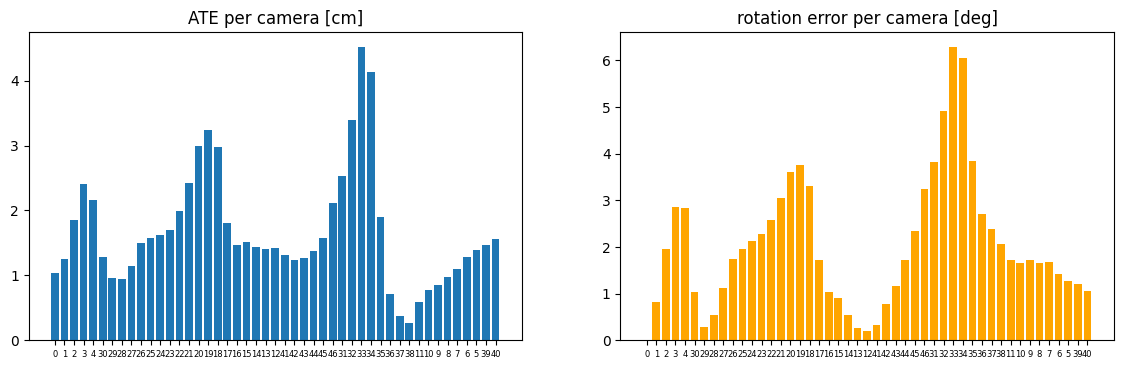

In [46]:
def align_sim3(A, B):
    mean_A = A.mean(axis=0)
    mean_B = B.mean(axis=0)
    A0 = A - mean_A
    B0 = B - mean_B

    U, S, Vt = np.linalg.svd(B0.T @ A0)
    D = np.eye(3)
    if np.linalg.det(U @ Vt) < 0:
        D[2, 2] = -1
    R = U @ D @ Vt
    s = np.trace(np.diag(S) @ D) / np.sum(A0 ** 2)
    t = mean_B - s * R @ mean_A
    return s, R, t


def rotation_angle(R):
    # angle of a rotation matrix in degrees
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))


# 1) ATE
s, R_al, t_al = align_sim3(centers, gt_centers)
aligned = (s * (R_al @ centers.T)).T + t_al

ate_cm = []
for k in range(len(order)):
    ate_cm.append(np.linalg.norm(aligned[k] - gt_centers[k]) * 100)
ate_cm = np.array(ate_cm)

# 2) rotation error (our poses are relative to camera 0, so compare with Rs[i] @ Rs[0].T)
rot_err = []
for k in range(len(order)):
    R_true = Rs[order[k]] @ Rs[0].T
    R_ours = poses[k][0]
    rot_err.append(rotation_angle(R_ours.T @ R_true))
rot_err = np.array(rot_err)

print(f"ATE  RMSE: {np.sqrt(np.mean(ate_cm ** 2)):.2f} cm | max: {ate_cm.max():.2f} cm")
print(f"rotation error mean: {rot_err.mean():.2f} deg | max: {rot_err.max():.2f} deg")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(len(order)), ate_cm)
axes[0].set_title("ATE per camera [cm]")
axes[1].bar(range(len(order)), rot_err, color="orange")
axes[1].set_title("rotation error per camera [deg]")
for ax in axes:
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, fontsize=6)
plt.show()

## Point cloud

Each 3D point gets the color of the pixel where it was first seen.
The result is saved as a PLY file (open it in MeshLab or CloudCompare).

saved 7730 points


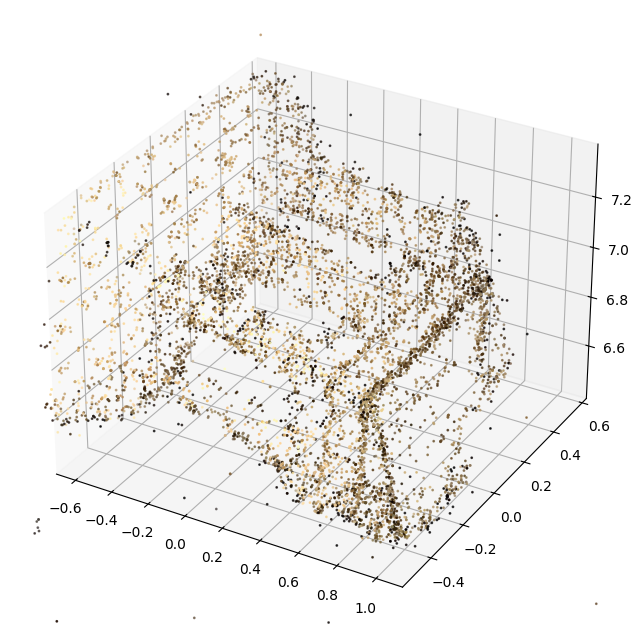

In [47]:
colors = np.zeros((len(X), 3), dtype=np.uint8)
has_color = np.zeros(len(X), dtype=bool)

color_images = {}
for k in range(len(obs_cam)):
    j = obs_point[k]
    if has_color[j]:
        continue
    img_id = order[obs_cam[k]]
    if img_id not in color_images:
        color_images[img_id] = cv2.cvtColor(cv2.imread(f"{image_folder}/{names[img_id]}"), cv2.COLOR_BGR2RGB)
    u, v = obs_pixel[k]
    colors[j] = color_images[img_id][int(round(v)), int(round(u))]
    has_color[j] = True

with open("temple_points.ply", "w") as f:
    f.write("ply\nformat ascii 1.0\n")
    f.write(f"element vertex {len(X)}\n")
    f.write("property float x\nproperty float y\nproperty float z\n")
    f.write("property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
    for p, c in zip(X, colors):
        f.write(f"{p[0]} {p[1]} {p[2]} {c[0]} {c[1]} {c[2]}\n")
print("saved", len(X), "points")

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=1, c=colors / 255)
ax.set_xlim(np.percentile(X[:, 0], 2), np.percentile(X[:, 0], 98))
ax.set_ylim(np.percentile(X[:, 1], 2), np.percentile(X[:, 1], 98))
ax.set_zlim(np.percentile(X[:, 2], 2), np.percentile(X[:, 2], 98))
plt.show()

## Dense reconstruction

Now that we know the camera poses, we can compute a depth for every pixel, not only for the SIFT points.

### Rectification
Two neighboring images are warped so that the same 3D point lies on the same line in both images.
Then the matching only has to search along one line.
Our camera moves up/down along the ring, so the lines are vertical. We rotate the images by 90° to make them horizontal.

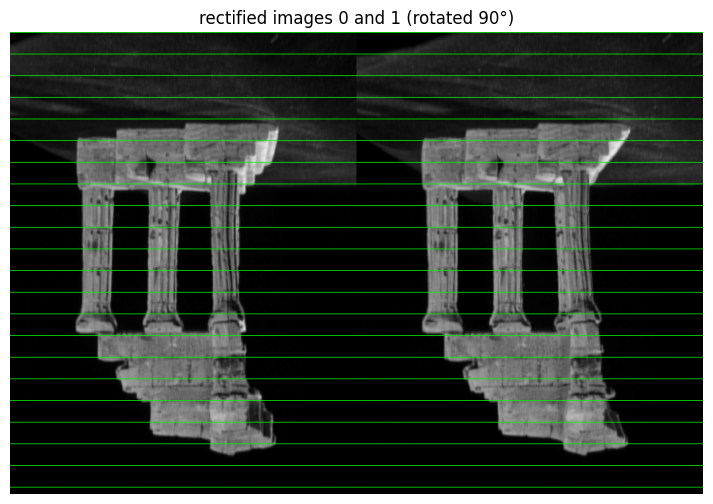

In [48]:
k = 0
i, j = order[k], order[k + 1]
img_a = cv2.imread(f"{image_folder}/{names[i]}", cv2.IMREAD_GRAYSCALE)
img_b = cv2.imread(f"{image_folder}/{names[j]}", cv2.IMREAD_GRAYSCALE)
h, w = img_a.shape

R_a, t_a = poses[k]
R_b, t_b = poses[k + 1]
R_ab = R_b @ R_a.T
T_ab = t_b - R_ab @ t_a

D = np.zeros(5)
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(K, D, K, D, (w, h), R_ab, T_ab, flags=0, alpha=0)

map_a = cv2.initUndistortRectifyMap(K, D, R1, P1, (w, h), cv2.CV_32FC1)
map_b = cv2.initUndistortRectifyMap(K, D, R2, P2, (w, h), cv2.CV_32FC1)
rect_a = cv2.remap(img_a, map_a[0], map_a[1], cv2.INTER_LINEAR)
rect_b = cv2.remap(img_b, map_b[0], map_b[1], cv2.INTER_LINEAR)

rot_a = cv2.rotate(rect_a, cv2.ROTATE_90_CLOCKWISE)
rot_b = cv2.rotate(rect_b, cv2.ROTATE_90_CLOCKWISE)

pair = cv2.cvtColor(np.hstack([rot_a, rot_b]), cv2.COLOR_GRAY2RGB)
for y in range(0, pair.shape[0], 30):
    cv2.line(pair, (0, y), (pair.shape[1], y), (0, 255, 0), 1)

plt.figure(figsize=(12, 6))
plt.imshow(pair)
plt.title(f"rectified images {i} and {j} (rotated 90°)")
plt.axis("off")
plt.show()

### Disparity

![Stereo disparity](disparity.png)

*Figure: Robert Collins, CMPEN454 lecture slides (Penn State).*

After rectification, the same point lies on the same line in both images. It only shifts along that line.
This shift is the disparity $d$. Depth and disparity are inversely proportional:

$$Z = \frac{f \cdot B}{d}$$

SGBM finds $d$ for every pixel by sliding a small window along the line and picking the position with the lowest cost.

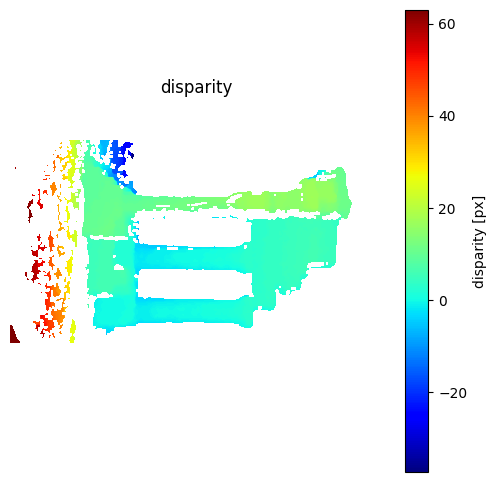

In [49]:
sgbm = cv2.StereoSGBM_create(minDisparity=-64, numDisparities=128, blockSize=5,
                             P1=8 * 5 * 5, P2=32 * 5 * 5, uniquenessRatio=10,
                             speckleWindowSize=100, speckleRange=2)

disp = sgbm.compute(rot_b, rot_a).astype(np.float32) / 16
disp = cv2.rotate(disp, cv2.ROTATE_90_COUNTERCLOCKWISE)

valid = (disp > -64) & (rect_a > 20)

plt.figure(figsize=(6, 6))
plt.imshow(np.where(valid, disp, np.nan), cmap="jet")
plt.colorbar(label="disparity [px]")
plt.title("disparity")
plt.axis("off")
plt.show()

#### One pixel by hand

We take a 9×9 patch around one pixel and slide it along the same line in the other image.
The sum of absolute differences (SAD) is lowest where the patches match.

SAD d: 1 | SGBM d: 0.9375


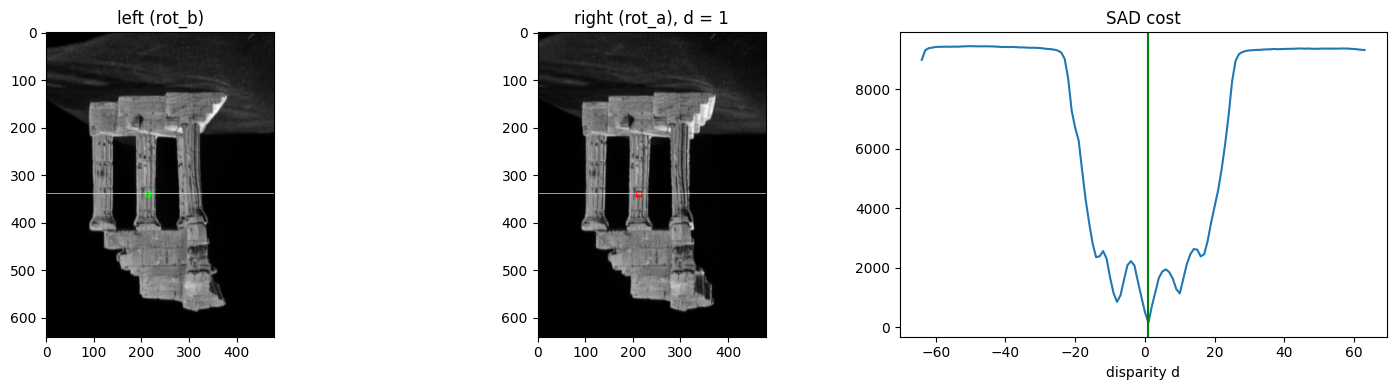

In [50]:
from matplotlib.patches import Rectangle

v, u = 338, 212
half = 4
box = 2 * half + 1

patch_left = rot_b[v - half:v + half + 1, u - half:u + half + 1].astype(np.float32)

candidates = []
costs = []
for d in range(-64, 64):
    x = u - d
    if x - half < 0 or x + half + 1 > rot_a.shape[1]:
        continue
    patch_right = rot_a[v - half:v + half + 1, x - half:x + half + 1].astype(np.float32)
    candidates.append(d)
    costs.append(np.abs(patch_left - patch_right).sum())

best_d = candidates[int(np.argmin(costs))]
disp_rot = cv2.rotate(disp, cv2.ROTATE_90_CLOCKWISE)
print("SAD d:", best_d, "| SGBM d:", disp_rot[v, u])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].imshow(rot_b, cmap="gray")
ax[0].add_patch(Rectangle((u - half, v - half), box, box, ec="lime", fill=False))
ax[0].axhline(v, color="yellow", lw=0.5)
ax[0].set_title("left (rot_b)")
ax[1].imshow(rot_a, cmap="gray")
ax[1].add_patch(Rectangle((u - best_d - half, v - half), box, box, ec="red", fill=False))
ax[1].axhline(v, color="yellow", lw=0.5)
ax[1].set_title(f"right (rot_a), d = {best_d}")
ax[2].plot(candidates, costs)
ax[2].axvline(best_d, color="green")
ax[2].set_xlabel("disparity d")
ax[2].set_title("SAD cost")
plt.tight_layout()
plt.show()

#### Depth map

$Z = f \cdot B / d$ with two details:
- `flags=0` moved the image centers apart, so we add their difference: $Z = f B / (d + d_0)$
- $B$ comes from our SfM, so $Z$ is in SfM units. The scale $s$ from the ATE alignment turns it into meters.

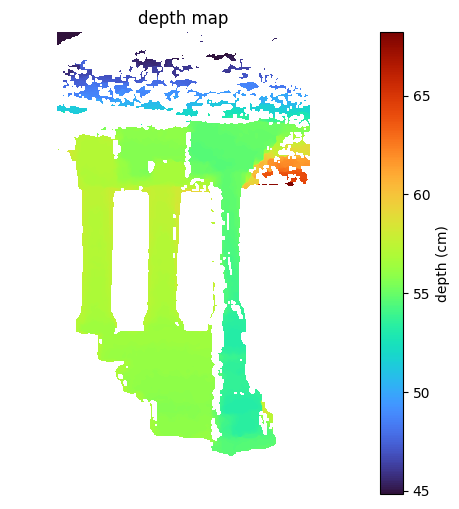

median depth: 55.9 cm


In [51]:
fB = abs(P2[1, 3])
d0 = P2[1, 2] - P1[1, 2]

depth = np.zeros_like(disp)
depth[valid] = fB / (disp[valid] + d0)

s_m, _, _ = align_sim3(centers, gt_centers)
depth_cm = depth * s_m * 100

plt.figure(figsize=(6, 6))
plt.imshow(cv2.rotate(np.where(valid, depth_cm, np.nan), cv2.ROTATE_90_CLOCKWISE), cmap="turbo")
plt.colorbar(label="depth (cm)")
plt.title("depth map")
plt.axis("off")
plt.show()

print("median depth:", np.median(depth_cm[valid]).round(1), "cm")

#### Left–right check

We compute the disparity twice: left → right and right → left. If the two answers do not agree (more than 1 px apart), the match is unreliable and we drop the pixel.

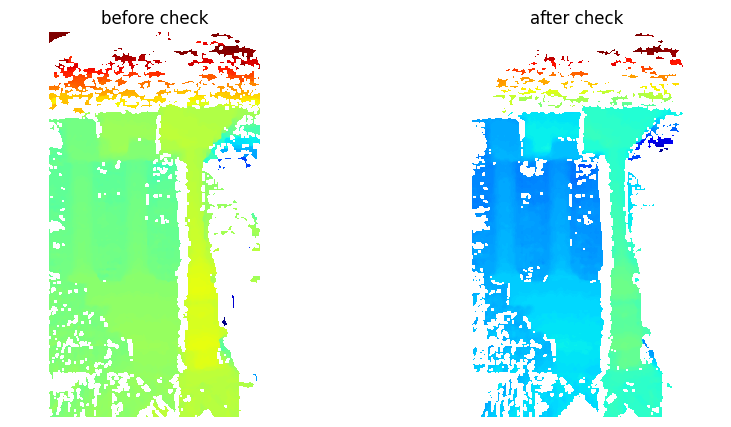

kept: 85.8 %


In [52]:
def disparity_with_check(left, right, max_diff=1):
    disp_l = sgbm.compute(left, right).astype(np.float32) / 16
    disp_r = sgbm.compute(cv2.flip(right, 1), cv2.flip(left, 1)).astype(np.float32) / 16
    disp_r = cv2.flip(disp_r, 1)

    H, W = disp_l.shape
    cols = np.tile(np.arange(W), (H, 1))
    match = np.clip(np.round(cols - disp_l).astype(int), 0, W - 1)
    disp_r_at_match = np.take_along_axis(disp_r, match, axis=1)

    consistent = np.abs(disp_l - disp_r_at_match) <= max_diff
    return disp_l, consistent


disp_l, consistent = disparity_with_check(rot_b, rot_a)
ok = disp_l > -64

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(np.where(ok, disp_l, np.nan), cmap="jet")
ax[0].set_title("before check")
ax[1].imshow(np.where(ok & consistent, disp_l, np.nan), cmap="jet")
ax[1].set_title("after check")
for a in ax:
    a.axis("off")
plt.show()

print("kept:", round((ok & consistent).sum() / ok.sum() * 100, 1), "%")

### Dense point cloud
For every neighboring pair: rectify → disparity → 3D points (`reprojectImageTo3D`) →
back to camera a (R1ᵀ) → world (Rₐᵀ (X − tₐ)).
Points are kept only if their depth is in the range of our sparse SIFT points.

`gap = 2` uses every second image as the pair: thinner surfaces, but about 3× fewer points.

In [53]:
def pair_to_points(k, step=2, gap=1):
    i, j = order[k], order[k + gap]
    img_a = cv2.imread(f"{image_folder}/{names[i]}")
    img_b = cv2.imread(f"{image_folder}/{names[j]}")
    gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
    gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

    R_a, t_a = poses[k]
    R_b, t_b = poses[k + gap]
    R_ab = R_b @ R_a.T
    T_ab = t_b - R_ab @ t_a

    R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(K, D, K, D, (w, h), R_ab, T_ab, flags=0, alpha=0)
    map_a = cv2.initUndistortRectifyMap(K, D, R1, P1, (w, h), cv2.CV_32FC1)
    map_b = cv2.initUndistortRectifyMap(K, D, R2, P2, (w, h), cv2.CV_32FC1)
    rect_a = cv2.remap(gray_a, map_a[0], map_a[1], cv2.INTER_LINEAR)
    rect_b = cv2.remap(gray_b, map_b[0], map_b[1], cv2.INTER_LINEAR)
    rect_color = cv2.remap(img_a, map_a[0], map_a[1], cv2.INTER_LINEAR)

    rot_a = cv2.rotate(rect_a, cv2.ROTATE_90_CLOCKWISE)
    rot_b = cv2.rotate(rect_b, cv2.ROTATE_90_CLOCKWISE)
    disp, consistent = disparity_with_check(rot_b, rot_a)
    disp = cv2.rotate(disp, cv2.ROTATE_90_COUNTERCLOCKWISE)
    consistent = cv2.rotate(consistent.astype(np.uint8), cv2.ROTATE_90_COUNTERCLOCKWISE) > 0

    points_rect = cv2.reprojectImageTo3D(disp, Q)

    depth_sparse = (R_a @ X.T + t_a)[2]
    z_min, z_max = np.percentile(depth_sparse, 1), np.percentile(depth_sparse, 99)

    valid = (disp > -64) & (rect_a > 20) & consistent
    pts = points_rect[valid][::step]
    cols = rect_color[valid][::step]

    pts_cam = (R1.T @ pts.T).T
    keep = (pts_cam[:, 2] > z_min) & (pts_cam[:, 2] < z_max)
    pts_world = (R_a.T @ (pts_cam[keep].T - t_a)).T
    return pts_world, cols[keep][:, ::-1]


gap = 1
dense_points = []
dense_colors = []
for k in range(len(order) - gap):
    pts, cols = pair_to_points(k, gap=gap)
    dense_points.append(pts)
    dense_colors.append(cols)
    print(f"pair {order[k]}-{order[k + gap]}: {len(pts)} points")

dense_points = np.vstack(dense_points)
dense_colors = np.vstack(dense_colors)
print("total dense points:", len(dense_points))

pair 0-1: 36622 points
pair 1-2: 42555 points
pair 2-3: 41218 points
pair 3-4: 45142 points
pair 4-30: 32529 points
pair 30-29: 43697 points
pair 29-28: 36450 points
pair 28-27: 39446 points
pair 27-26: 40932 points
pair 26-25: 39906 points
pair 25-24: 38483 points
pair 24-23: 37397 points
pair 23-22: 36688 points
pair 22-21: 35065 points
pair 21-20: 35967 points
pair 20-19: 38794 points
pair 19-18: 36079 points
pair 18-17: 30478 points
pair 17-16: 29880 points
pair 16-15: 32791 points
pair 15-14: 40814 points
pair 14-13: 42737 points
pair 13-12: 44739 points
pair 12-41: 0 points
pair 41-42: 51224 points
pair 42-43: 48181 points
pair 43-44: 47738 points
pair 44-45: 47073 points
pair 45-46: 48418 points
pair 46-31: 51772 points
pair 31-32: 43756 points
pair 32-33: 46045 points
pair 33-34: 42697 points
pair 34-35: 46135 points
pair 35-36: 46170 points
pair 36-37: 40684 points
pair 37-38: 40652 points
pair 38-11: 0 points
pair 11-10: 30934 points
pair 10-9: 27542 points
pair 9-8: 29521 po

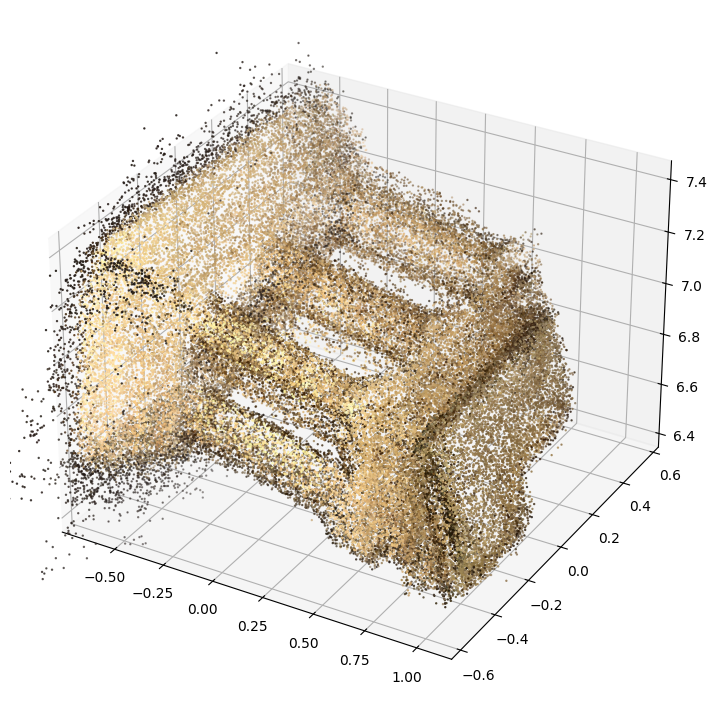

saved temple_dense.ply


In [54]:
rng = np.random.default_rng(0)
show = rng.choice(len(dense_points), min(60000, len(dense_points)), replace=False)

fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(projection="3d")
ax.scatter(dense_points[show, 0], dense_points[show, 1], dense_points[show, 2],
           s=0.5, c=dense_colors[show] / 255)
ax.set_xlim(np.percentile(dense_points[:, 0], 1), np.percentile(dense_points[:, 0], 99))
ax.set_ylim(np.percentile(dense_points[:, 1], 1), np.percentile(dense_points[:, 1], 99))
ax.set_zlim(np.percentile(dense_points[:, 2], 1), np.percentile(dense_points[:, 2], 99))
plt.show()

with open("temple_dense.ply", "w") as f:
    f.write("ply\nformat ascii 1.0\n")
    f.write(f"element vertex {len(dense_points)}\n")
    f.write("property float x\nproperty float y\nproperty float z\n")
    f.write("property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
    for p, c in zip(dense_points, dense_colors):
        f.write(f"{p[0]:.5f} {p[1]:.5f} {p[2]:.5f} {c[0]} {c[1]} {c[2]}\n")
print("saved temple_dense.ply")

## Surface reconstruction (Poisson)

The dense cloud is only points. Poisson reconstruction turns it into a surface (a triangle mesh):
it fits a smooth, closed surface whose normals agree with the normals of the points.

Before that we prepare the points:
- Rotate the cloud so that the ring of cameras is horizontal (up = z)
- Voxel downsampling: one point per small cube, so the meshing is faster
- Remove isolated points (statistical outlier removal)
- Normals: the direction the surface faces at every point

Poisson always closes the surface, so it also fills places where there are no points.
We remove those parts by cutting the vertices with the lowest point density.
This cell takes 1–2 minutes.

In [55]:
import os
import sys
import open3d as o3d

o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)

ring_center = centers.mean(axis=0)
_, _, Vt = np.linalg.svd(centers - ring_center)
R_up = Vt.copy()
if np.linalg.det(R_up) < 0:
    R_up[2] = -R_up[2]
points_up = (R_up @ (dense_points - ring_center).T).T

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(points_up)
pcd.colors = o3d.utility.Vector3dVector(dense_colors / 255)

size = np.percentile(points_up, 99, axis=0) - np.percentile(points_up, 1, axis=0)
voxel = size.max() / 250
pcd = pcd.voxel_down_sample(voxel)
pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

pcd.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=voxel * 4, max_nn=30))
pcd.orient_normals_consistent_tangent_plane(15)

# Poisson prints C++ warnings ("bad average roots") straight to the output -> We Send them to /dev/null.
sys.stdout.flush()
sys.stderr.flush()
devnull = os.open(os.devnull, os.O_WRONLY)
saved_out = os.dup(1)
saved_err = os.dup(2)
os.dup2(devnull, 1)
os.dup2(devnull, 2)
mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(pcd, depth=9, n_threads=1)
os.dup2(saved_out, 1)
os.dup2(saved_err, 2)
os.close(devnull)
densities = np.asarray(densities)
mesh.remove_vertices_by_mask(densities < np.quantile(densities, 0.05))

o3d.io.write_triangle_mesh("temple_mesh.ply", mesh)
print("points:", len(pcd.points), "| triangles:", len(mesh.triangles))
print("saved temple_mesh.ply")

points: 786358 | triangles: 3555778
saved temple_mesh.ply


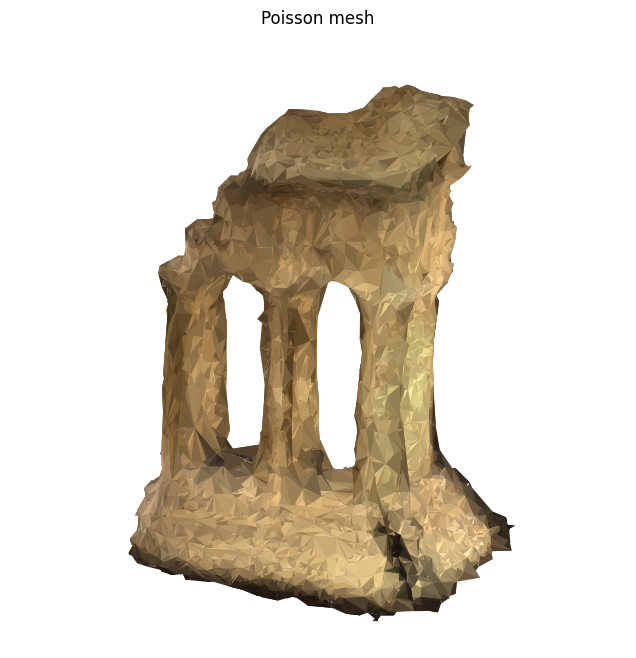

In [56]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

small = mesh.simplify_quadric_decimation(60000)
small.compute_triangle_normals()
v = np.asarray(small.vertices)
tri = np.asarray(small.triangles)
normals = np.asarray(small.triangle_normals)

light = np.array([0.4, -0.6, 0.7])
light = light / np.linalg.norm(light)
shade = 0.35 + 0.65 * np.abs(normals @ light)
face_colors = np.asarray(small.vertex_colors)[tri].mean(axis=1)
face_colors = np.clip(face_colors * (0.55 + 0.6 * shade[:, None]), 0, 1)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
ax.add_collection3d(Poly3DCollection(v[tri], facecolors=face_colors, edgecolor="none"))
lo = np.percentile(v, 1, axis=0)
hi = np.percentile(v, 99, axis=0)
ax.set_xlim(lo[0], hi[0])
ax.set_ylim(lo[1], hi[1])
ax.set_zlim(lo[2], hi[2])
ax.set_box_aspect(hi - lo)
ax.view_init(elev=15, azim=35)
ax.axis("off")
plt.title("Poisson mesh")
plt.show()